# Datenstrukturen: Python-Listen

Bisher hat jede Variable auf genau einen Wert verwiesen: eine Zahl,
einen String oder eine Grafik. Mit Python-Listen lernen wir eine erste
Datenstruktur kennen. Eine Datenstruktur fasst mehrere Werte nach einem
bestimmten Ordnungsprinzip zusammen, bei der Liste in einer festen
Reihenfolge, und ermöglicht es, diese Werte gezielt anzusprechen und zu
bearbeiten. 

Bearbeitet werden Listen einerseits mit eingebauten Funktionen wie len()
und mit Operatoren wie [], andererseits mit sogenannten Methoden.
Methoden sind Funktionen, die zu einem bestimmten Datentyp gehören und
mit einem Punkt direkt auf einem Wert aufgerufen werden, z. B.
einkaufsliste.append('Brot'). Im Unterschied zu den bisher verwendeten
Funktionen verändern viele Listenmethoden die Liste direkt, statt ein
neues Resultat zurückzugeben.

::: {.callout-note title="INFO Python-Listen sind dynamische Arrays"}

**Was ist ein Array?**

Ein Array ist eine der grundlegendsten Datenstrukturen der Informatik. Man
kann es sich wie eine Reihe von nummerierten Schliessfächern vorstellen, die
lückenlos nebeneinander im Arbeitsspeicher liegen. Alle Fächer sind gleich
gross, und jedes hat eine Nummer, den sogenannten *Index*.

Weil die Fächer lückenlos aneinandergereiht und gleich gross sind, kann der
Computer die Position jedes Fachs direkt berechnen:

Position = Anfang des Arrays + Index · Grösse eines Fachs

Der Computer muss also nicht alle Fächer der Reihe nach durchsuchen, um das
gewünschte zu finden. Der Zugriff auf das tausendste Element dauert gleich
lang wie der Zugriff auf das erste. Diese Berechnung erklärt übrigens auch,
weshalb in Python mit 0 zu zählen begonnen wird: Der Index gibt an, wie viele
Fächer vom Anfang aus übersprungen werden. Das erste Element liegt direkt am
Anfang, also bei Index 0.

**Das Problem: Ein Array hat eine feste Grösse**

Ein klassisches Array wird mit einer festen Anzahl Fächer angelegt. Ist es
voll, kann es nicht einfach verlängert werden, denn der Speicherplatz direkt
dahinter ist möglicherweise bereits anderweitig belegt.

**Die Lösung: Das dynamische Array**

Python löst dieses Problem mit einem Trick. Beim Anlegen einer Liste
reserviert Python etwas mehr Fächer, als im Moment gebraucht werden. Neue
Elemente können so am Ende einfach in ein freies Fach gelegt werden. Erst wenn
alle reservierten Fächer belegt sind, sucht Python einen neuen, grösseren
Speicherbereich, kopiert alle bisherigen Elemente dorthin und gibt den alten
Bereich frei. Für uns geschieht das unsichtbar: Die Liste scheint einfach
beliebig wachsen zu können. Deshalb spricht man von einem *dynamischen* Array.

**Was das für die Praxis bedeutet**

- Der Zugriff über den Index (`liste[5]`) ist immer schnell, egal wie lang die
  Liste ist.
- Das Anhängen am Ende (`liste.append(x)`) ist in aller Regel schnell.
- Das Einfügen oder Entfernen am Anfang oder in der Mitte einer Liste ist
  dagegen aufwendig: Alle nachfolgenden Elemente müssen um ein Fach verschoben
  werden. Bei langen Listen kann das spürbar Zeit kosten.

Warum dieser Unterschied wichtig ist, wird beim Thema *Beurteilung von
Algorithmen* noch genauer betrachtet.

:::

::: {.callout-tip collapse="true"}
## Vertiefung: Warum kann eine Liste Werte unterschiedlicher Typen enthalten?

Eine Zahl braucht weniger Speicherplatz als ein langer Text. Wie passt das
zu gleich grossen Fächern? In den Fächern einer Python-Liste liegen nicht die
Werte selbst, sondern Verweise auf die Orte im Arbeitsspeicher, an denen die
Werte abgelegt sind, genau wie bei Variablen. Alle Verweise sind gleich gross,
unabhängig davon, worauf sie zeigen. Deshalb kann eine Liste problemlos Zahlen,
Strings und sogar PyTamaro-Grafiken gleichzeitig enthalten.

:::

## Elemente hinzufügen: Die Methode `.append()`

Eine Liste wird mit eckigen Klammern angelegt. Die einzelnen Elemente werden
durch Kommas getrennt.

```{python}
einkaufsliste = ['Brot', 'Milch']
einkaufsliste
```

Häufig steht beim Anlegen einer Liste noch nicht fest, welche Elemente sie
später enthalten soll. Eine Liste kann deshalb auch leer angelegt und
anschliessend schrittweise gefüllt werden. Dafür stellt Python die Methode
`.append()` zur Verfügung. Sie hängt das als Argument übergebene Element am
Ende der Liste an.

```{python}
einkaufsliste.append('Käse')
einkaufsliste
```

Beachten Sie die Schreibweise: Die Methode wird mit einem Punkt direkt an den
Namen der Liste angehängt. Damit ist klar, *welche* Liste verändert werden
soll.

::: {.callout-warning title="Achtung: `.append()` verändert die Liste direkt"}

Bei PyTamaro haben Sie sich daran gewöhnt, das Resultat einer Funktion einer
Variablen zuzuweisen:

```python
blume = kombiniere(blume, bluetenblatt_gedreht)
```

`kombiniere()` verändert die bestehende Grafik nicht, sondern erstellt eine
neue. Diese muss deshalb in einer Variablen gespeichert werden.

`.append()` funktioniert anders: Die Methode verändert die bestehende Liste
direkt und gibt kein Resultat zurück, genauer gesagt den speziellen Wert
`None` (engl. für *nichts*). Wer das Muster von PyTamaro überträgt, verliert
seine Liste:

```{python}
einkaufsliste = einkaufsliste.append('Eier')  # FALSCH!
print(einkaufsliste)
```

Die Variable `einkaufsliste` verweist jetzt nicht mehr auf die Liste, sondern
auf `None`. Richtig ist deshalb immer:

```python
einkaufsliste.append('Eier')  # richtig: ohne Zuweisung
```

:::

Besonders nützlich wird `.append()` in Kombination mit einer For-Schleife. Im
folgenden Beispiel wird eine leere Liste angelegt und in jedem
Schleifendurchlauf um eine Quadratzahl ergänzt.

```{python}
quadratzahlen = []

for zahl in range(1, 6):
    quadratzahlen.append(zahl ** 2)

quadratzahlen
```

```{python}
# TODO: Legen Sie eine leere Liste an und füllen Sie sie mit einer
# For-Schleife mit allen Vielfachen von 7 zwischen 7 und 70.
```

## Über Listen iterieren

Bisher haben wir For-Schleifen ausschliesslich mit `range()` verwendet. Eine
For-Schleife kann aber über jede Liste laufen. Die Schleifenvariable nimmt
dabei in jedem Durchlauf der Reihe nach den Wert des nächsten Elements an.
Man sagt, die Schleife *iteriert* über die Liste.

```{python}
for artikel in einkaufsliste:
    print(artikel)
```

Das ist kein Sonderfall: Auch `range(5)` liefert der Schleife einfach der
Reihe nach die Werte 0, 1, 2, 3 und 4. Eine Liste liefert stattdessen ihre
Elemente.

### Namenskonventionen

Python ist es gleichgültig, wie die Schleifenvariable heisst. Für Menschen,
die den Code lesen, macht der Name dagegen einen grossen Unterschied. Es haben
sich deshalb die folgenden Konventionen eingebürgert:

- **Listen erhalten einen Namen im Plural**, weil sie mehrere Elemente
  enthalten: `farben`, `zahlen`, `namen`. Alternativ kann ein Sammelbegriff
  verwendet werden, wie bei `einkaufsliste`.
- **Die Schleifenvariable erhält den passenden Namen im Singular**, weil sie
  in jedem Durchlauf genau *ein* Element bezeichnet: `for farbe in farben`,
  `for zahl in zahlen`, `for name in namen`.
- **Einbuchstabige Namen wie `i` werden nur für Zähler verwendet**, also wenn
  die Schleife mit `range()` über Zahlen läuft, die eine Position oder eine
  Anzahl Wiederholungen bezeichnen. Diese Konvention stammt aus der
  Mathematik, wo `i` traditionell für einen Index steht.

Vergleichen Sie die beiden folgenden Schleifen. Sie tun genau dasselbe, aber
nur bei der zweiten ist auf den ersten Blick klar, was passiert.

```python
for i in x:
    print(i)

for artikel in einkaufsliste:
    print(artikel)
```

Gut gewählte Namen machen den Code fast zu einem lesbaren Satz: *Für jeden
Artikel in der Einkaufsliste: gib den Artikel aus.*

### Anwendung mit PyTamaro

Als Anwendungsübung bauen wir einen animierten PacMan.

![PacMan](pacman.png)

In [1]:
from pytamaro.de import *

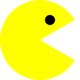

In [11]:
hintergrund = ellipse(80, 80, transparent)
pacman = kreis_sektor(40, 300, gelb)
pacman = drehe(30, pacman)
pacman = fixiere(mitte_links, pacman)
hintergrund = fixiere(mitte_links, hintergrund)
pacman = kombiniere(pacman, hintergrund)
auge = ellipse(10, 10, schwarz)
auge_positionshalter = rechteck(30, 20, transparent)
auge_positionshalter = fixiere(unten_links, auge_positionshalter)
auge = kombiniere(auge, auge_positionshalter)
auge = fixiere(oben_rechts, auge)
pacman = fixiere(oben_rechts, pacman)
pacman = kombiniere(auge, pacman)
zeige_grafik(pacman)
speichere_grafik('pacman.png', pacman)